## Two Months of Driver Strategy Adaptation (Flag 9)

### Dataset Overview
A constructed single-driver Porto Taxi case spanning June and July. Driver activity, linked GPS trajectories, citywide afternoon orders, Friday labels, and all-taxi C-stand request records support comparisons between early and later operating periods.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how a taxi driver’s operating strategy changes over two months of observed work, and assess whether the changes are consistent with learning from recurring demand and route conditions.

Role: Taxi operations analyst


Category: Experience-conditioned driver strategy, market discovery, and route execution

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [2]:
dataset_path = "driver_activity_segments.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [3]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do the driver’s 13:00–18:00 cruising paths and street-hail order locations change from the early to later period, and what recurring A–B pattern is visible early?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

experience_period  region                       operating_state  
early              Afternoon-to-stand transfer  cruising              2
                   East Station (B)             driving_to_pickup     8
                                                idle_wait             4
                                                passenger_trip        8
                   Riverside Market (A)         driving_to_pickup    12
                                                idle_wait             6
                                                passenger_trip       12
                   citywide cruising            cruising             20
                   other city district          driving_to_pickup    16
                                                idle_wait             6
                                                passenger_trip       16
later              Afternoon-to-stand transfer  cruising              2
                   A–B service pair             cruising             3

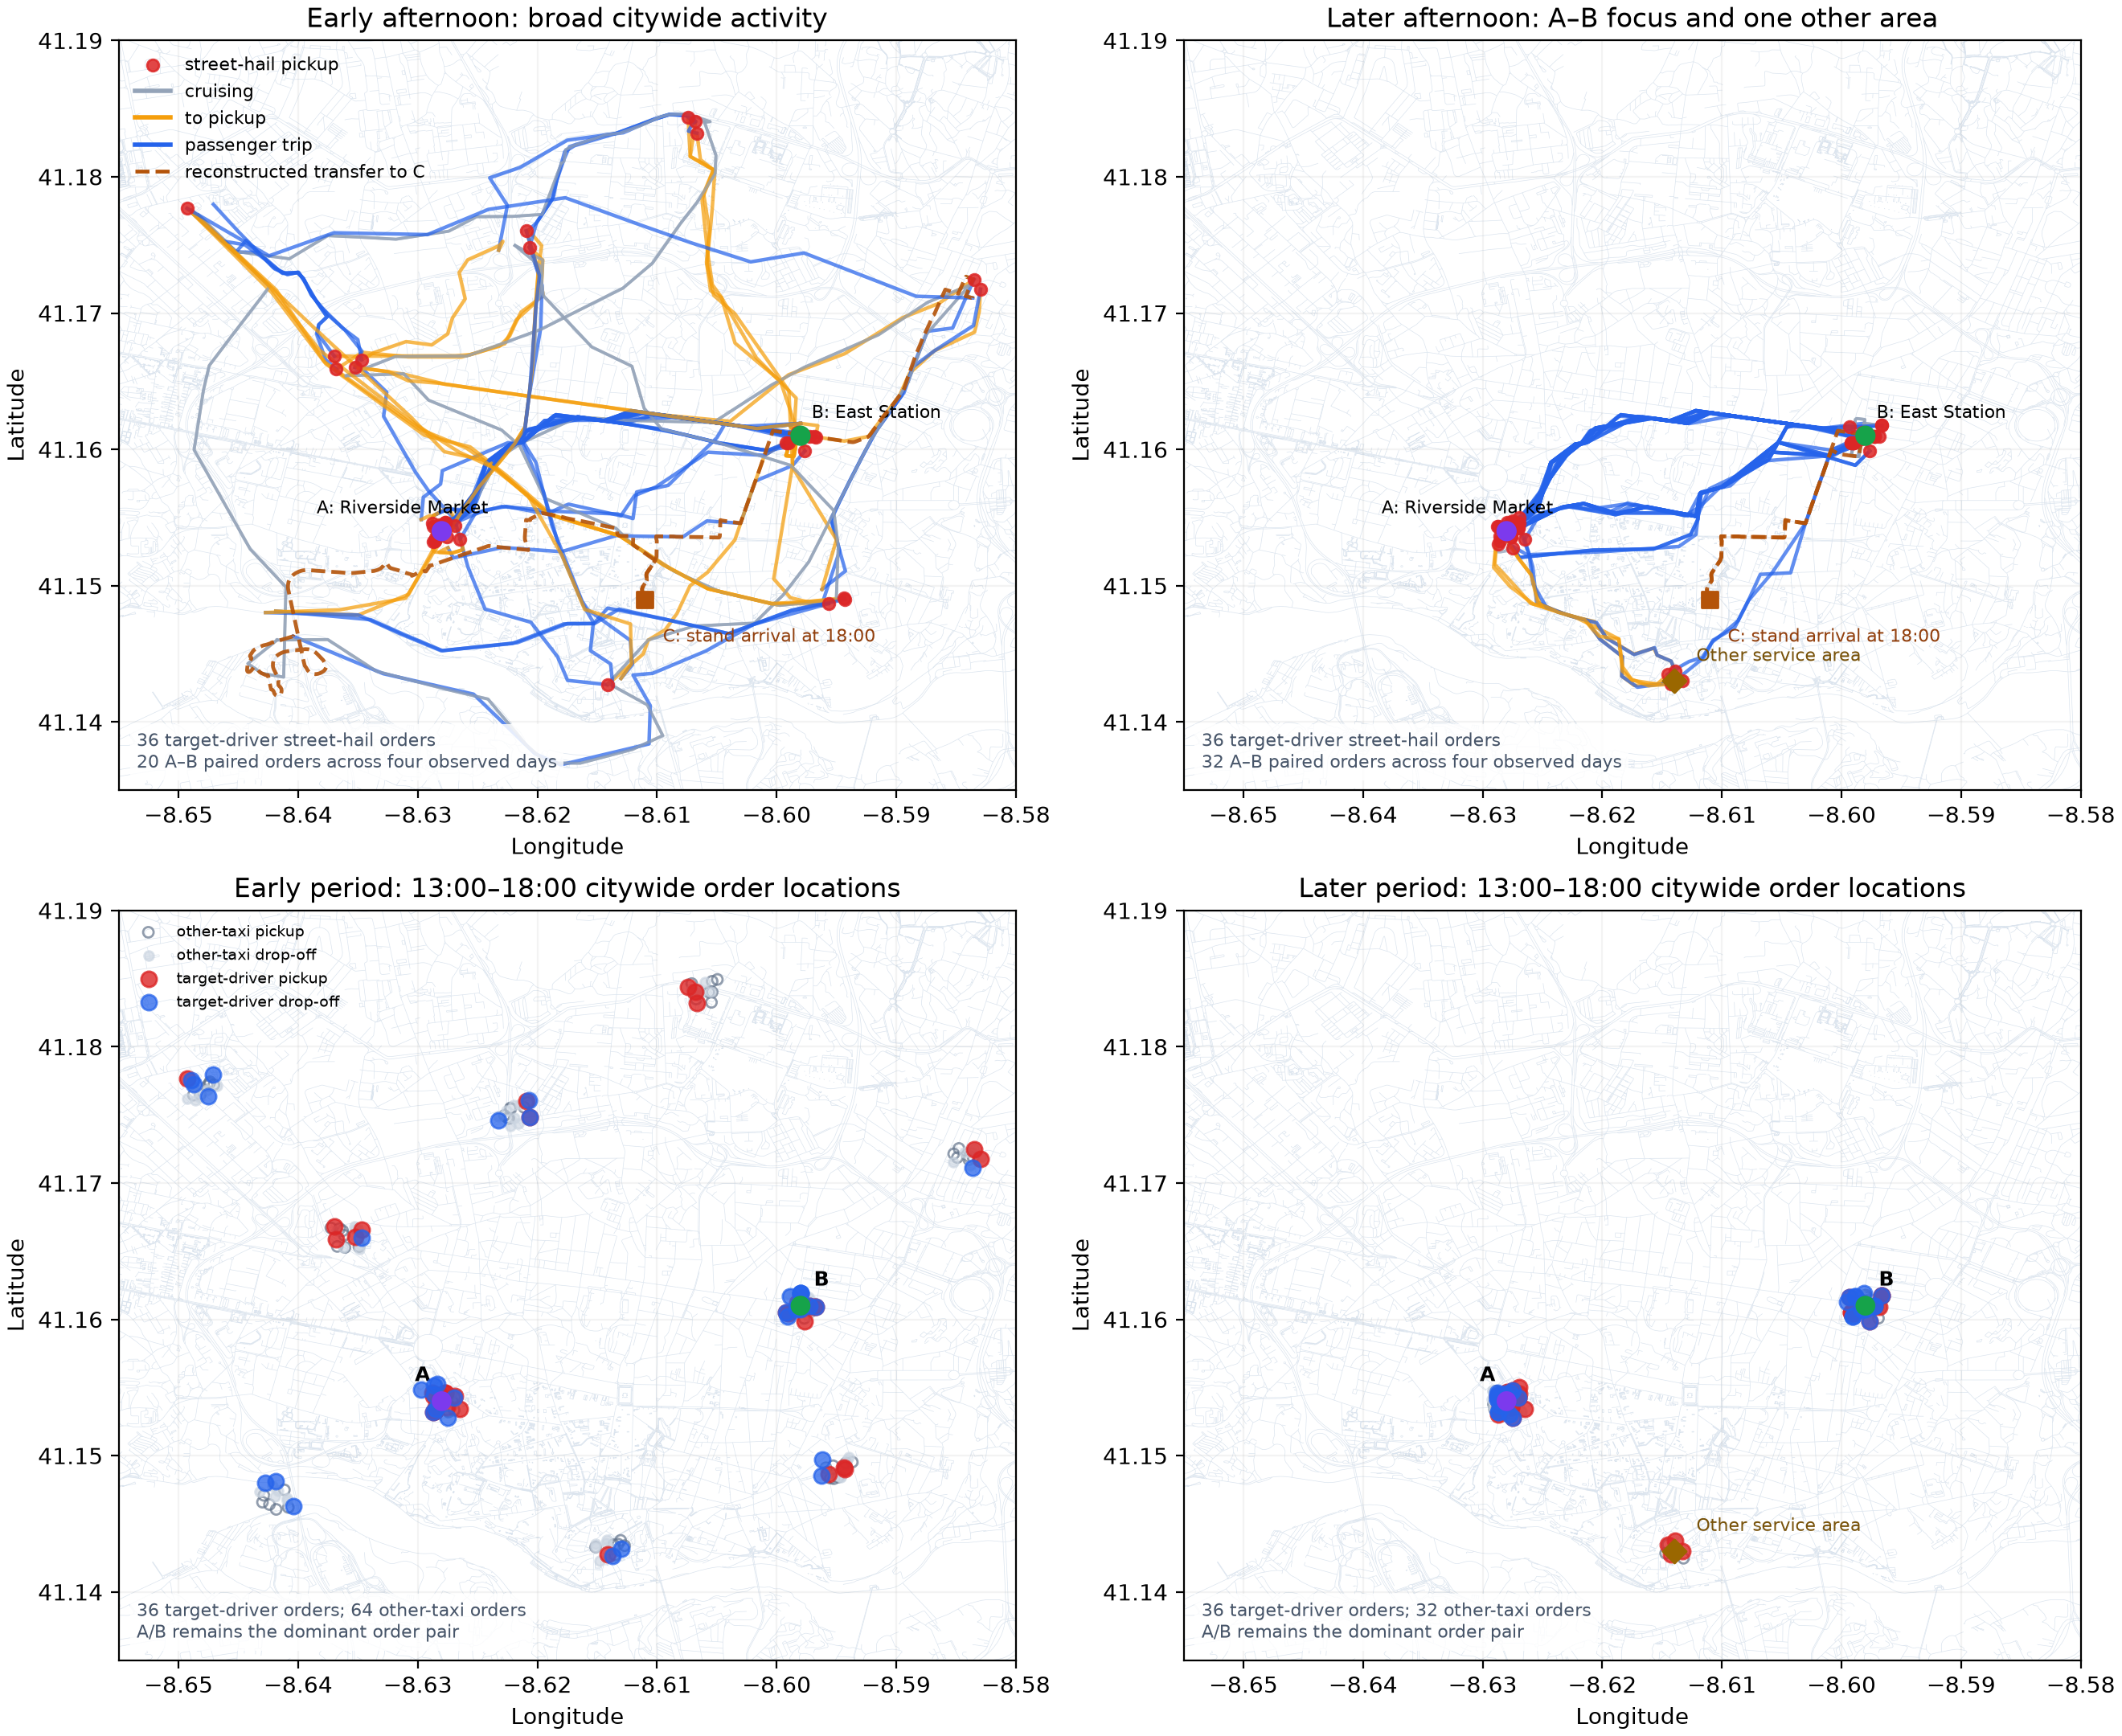

In [4]:
d=df.copy(); print(d[(d.time_period=='13:00–18:00')].groupby(['experience_period','region','operating_state']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/early_discovery_later_ab_focus.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "experience_conditioned_spatial_service_focus",
  "insight": "The driver’s afternoon activity shifts from broad cruising to a more concentrated pattern around recurring service areas.",
  "plot": {
    "plot_type": "early_later_trajectory_and_order_location_maps",
    "file": "visualizations/early_discovery_later_ab_focus.png",
    "title": "From Broad Cruising to an A–B Service Focus",
    "description": "Trajectory maps and separate 13:00–18:00 pickup/drop-off maps contrast early citywide exploration with later A–B concentration."
  },
  "question": "How do the driver’s 13:00–18:00 cruising paths and street-hail order locations change from the early to later period, and what recurring A–B pattern is visible early?",
  "code": "d=df.copy(); print(d[(d.time_period=='13:00–18:00')].groupby(['experience_period','region','operating_state']).size())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "operating_state",
    "trajectory_timestamp",
    "gps_position",
    "driver_id",
    "request_time",
    "trajectory_id"
  ]
}

### **Question 2**: What does the all-taxi request data show about Central Arena Stand demand on Friday evenings, and how does the driver’s behavior at the stand change later?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

day_type   service_date
Friday     2026-06-05      60
           2026-06-12      63
           2026-07-03      60
           2026-07-10      64
Tuesday    2026-06-02       5
           2026-06-09       4
Wednesday  2026-07-01       5
           2026-07-08       4
dtype: int64
<IPython.core.display.Image object>


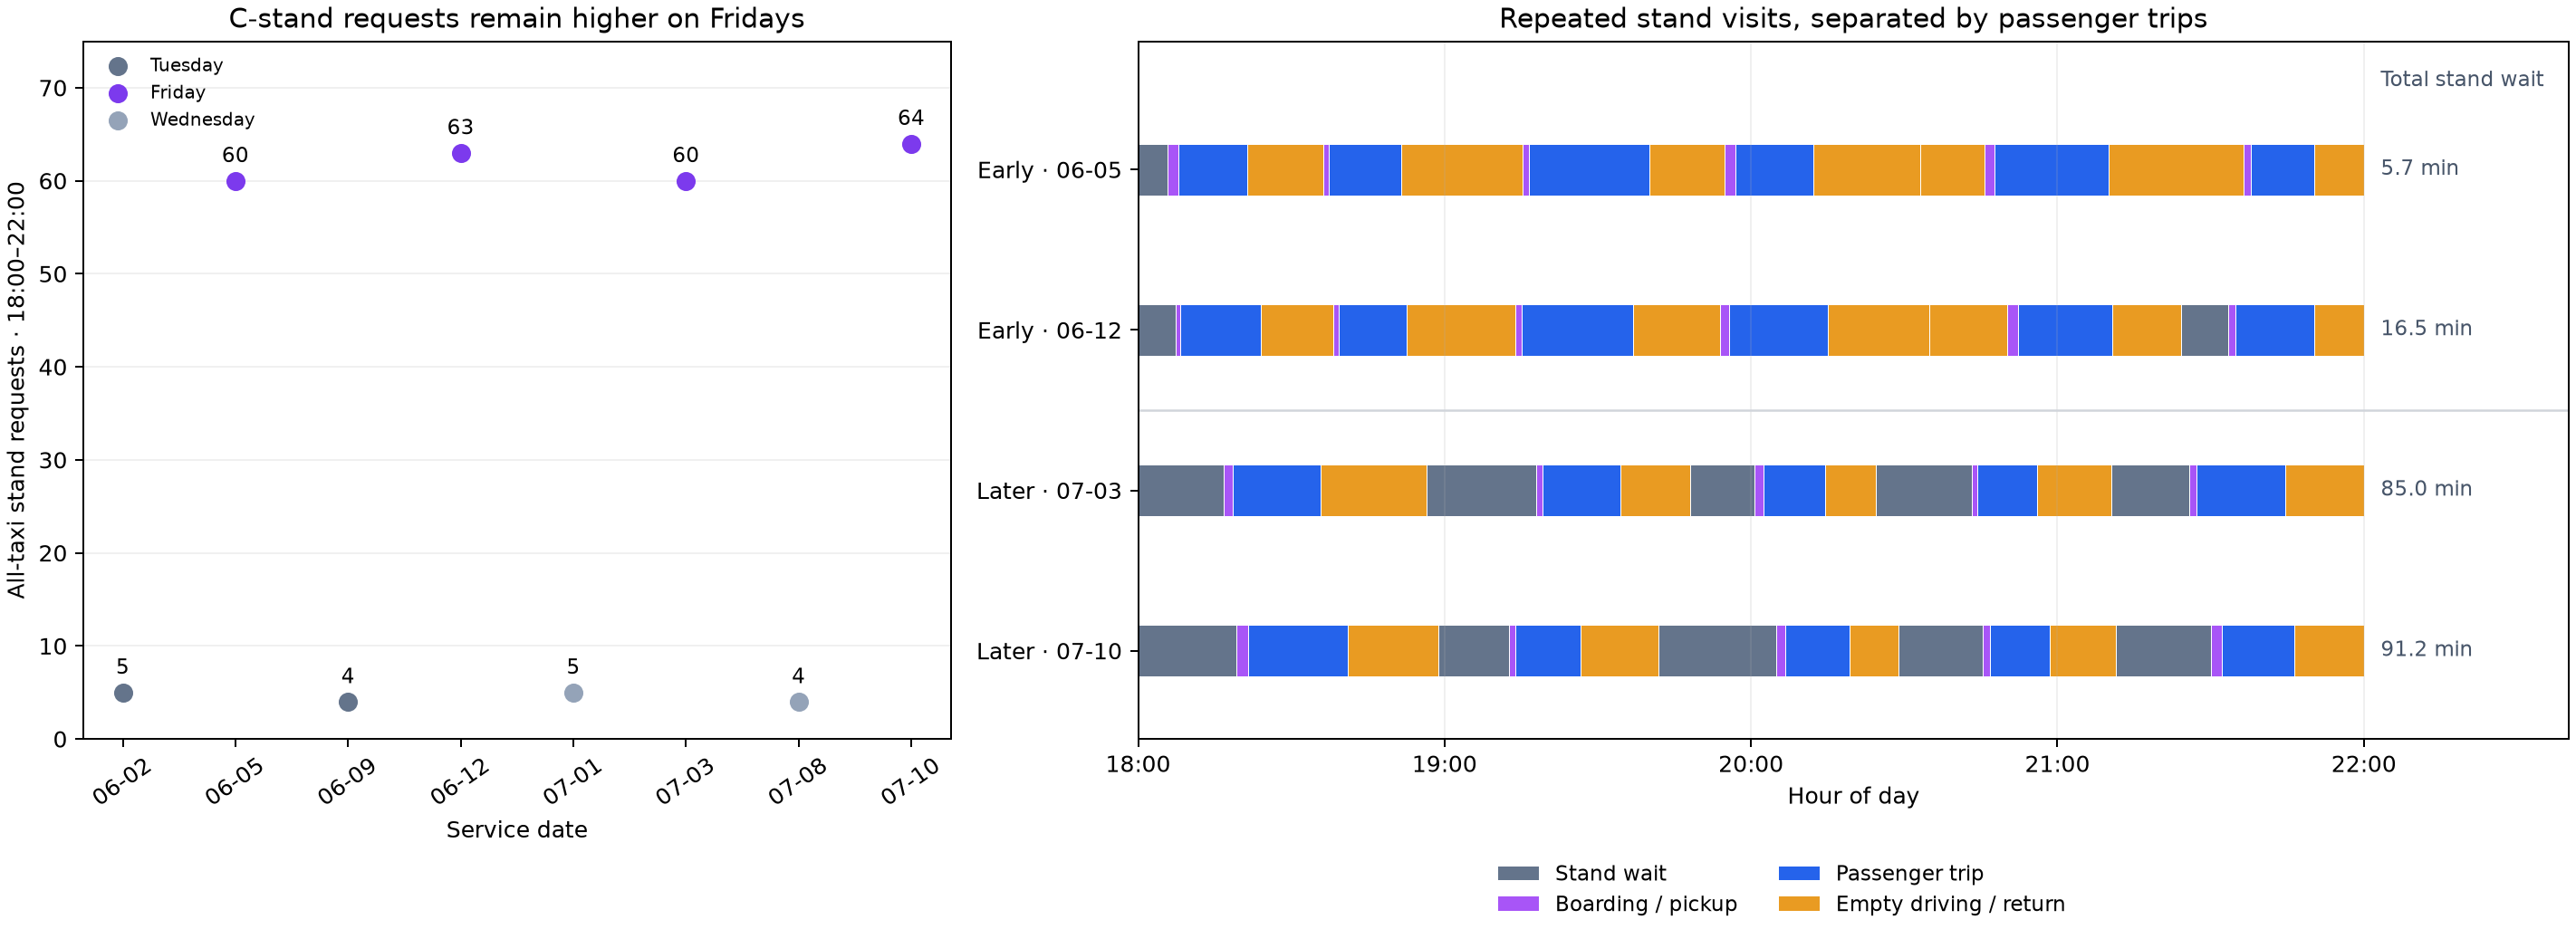

In [5]:
m=pd.read_csv('stand_market_requests.csv'); print(m.groupby(['day_type','service_date']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/friday_c_stand_demand_and_later_waiting.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "market_demand_and_taxi_stand_waiting",
  "insight": "On Friday evenings, the driver’s activity becomes more focused on a taxi stand, with longer waits in the later period.",
  "plot": {
    "plot_type": "market_demand_scatter_and_driver_state_timeline",
    "file": "visualizations/friday_c_stand_demand_and_later_waiting.png",
    "title": "Friday C-Stand Demand and Later Waiting",
    "description": "All-taxi market requests establish the Friday stand-demand pattern; the driver timeline compares early and later Friday behavior."
  },
  "question": "What does the all-taxi request data show about Central Arena Stand demand on Friday evenings, and how does the driver’s behavior at the stand change later?",
  "code": "m=pd.read_csv('stand_market_requests.csv'); print(m.groupby(['day_type','service_date']).size())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "operating_state",
    "trajectory_timestamp",
    "gps_position",
    "stand_position",
    "driver_id",
    "request_time",
    "trajectory_id"
  ]
}

### **Question 3**: For trips made between 06:00 and 09:00, how do route indirectness, speed level, and speed stability compare between the early and later observation periods?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

                  route_indirectness            ...  speed_cv          
                               count      mean  ...       75%       max
experience_period                               ...                    
early                           16.0  1.106068  ...  0.306105  0.348094
later                           16.0  1.106068  ...  0.051155  0.058820

[2 rows x 24 columns]
<IPython.core.display.Image object>


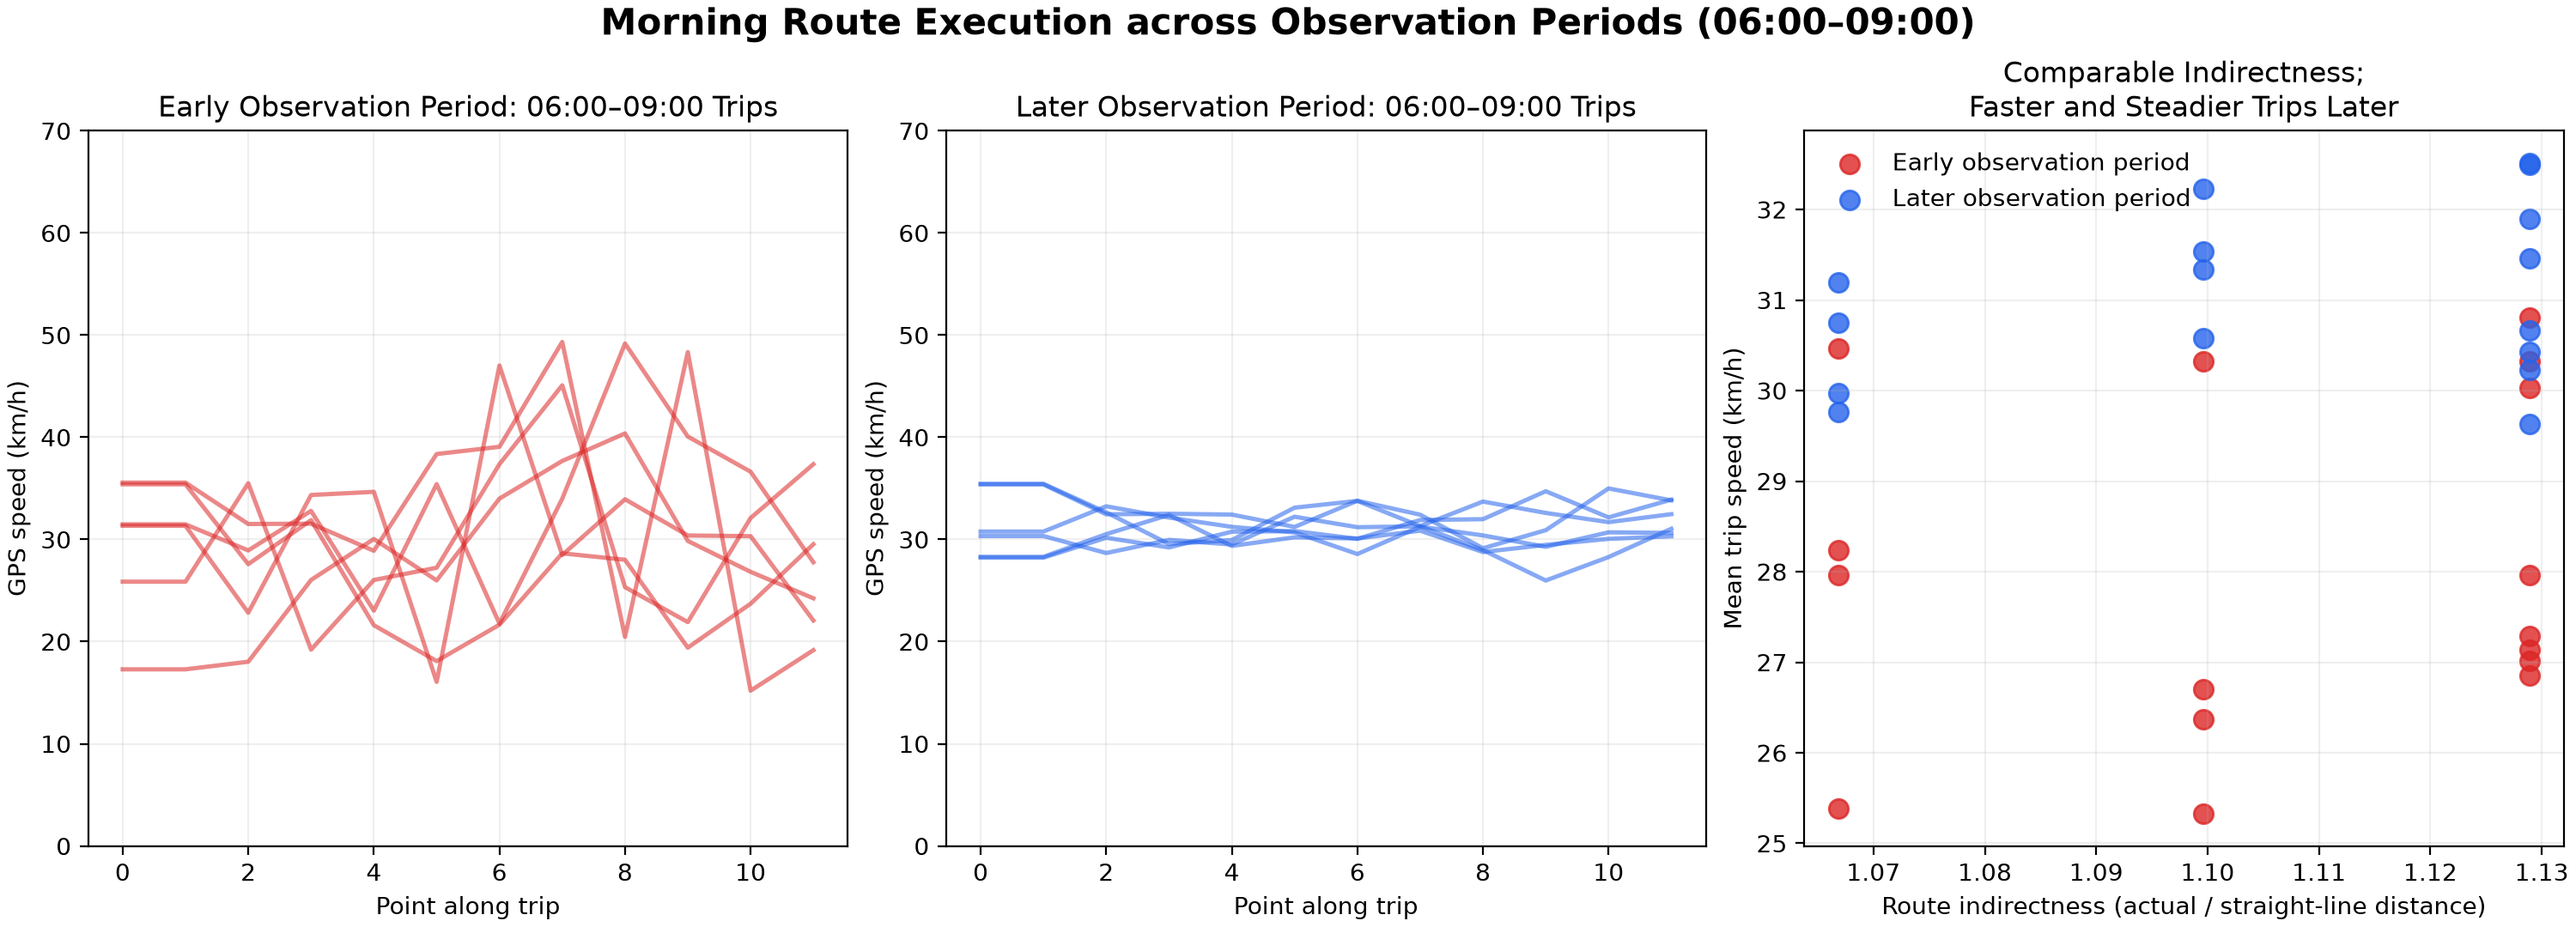

In [6]:
d=df[(df.time_period=='06:00–09:00') & (df.operating_state=='passenger_trip')]; print(d.groupby('experience_period')[['route_indirectness','mean_speed_kmh','speed_cv']].describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/morning_indirect_speed_adaptation.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "experience_conditioned_indirect_route_execution",
  "insight": "Morning trips in the later period are faster and have more stable speed profiles, while route indirectness remains similar.",
  "plot": {
    "plot_type": "speed_profile_and_indirectness_scatter",
    "file": "visualizations/morning_indirect_speed_adaptation.png",
    "title": "Morning Route Execution across Observation Periods (06:00–09:00)",
    "description": "Point-speed profiles and trip summaries compare route indirectness, speed level, and speed stability across the two observation periods."
  },
  "question": "For trips made between 06:00 and 09:00, how do route indirectness, speed level, and speed stability compare between the early and later observation periods?",
  "code": "d=df[(df.time_period=='06:00–09:00') & (df.operating_state=='passenger_trip')]; print(d.groupby('experience_period')[['route_indirectness','mean_speed_kmh','speed_cv']].describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "point_speed",
    "driver_id",
    "operating_state"
  ]
}

### Summary of Findings (Flag 9)

Over two observed months, this driver’s behavior changes in ways consistent with learning recurring market and route conditions. Later 13:00–18:00 work remains centered on the A–B street-hail pair despite a smaller set of non-A/B orders; later Friday evenings involve substantially longer C-stand waiting; and later indirect morning trips are steadier while maintaining a relatively high speed level.